# 02 — Modular physical signals

This notebook defines the reusable observations used later by scenario detection and anchor selection. It does not assign possession labels.

- **Observation:** measure geometry and ball motion from tracking.
- **Pattern:** inspect how those measurements change over consecutive frames.
- **Proxy:** name the football interpretation suggested by the pattern.
- **Decision:** leave possession assignment to scenarios, anchors, and the decoder.

If supplied, George is attached here through the shared adapter. Evidence-only mode preserves tactical coordinates and adds source, `sigma_m`, flight, speed, distance, and dead-ball observations before downstream scenarios and transitions. The feature builder performs a base scenario pass from observations first, then an anchor-informed scenario refinement; this prevents ownership labels from defining their own evidence. Haiqal's raw clues can be attached at this same feature boundary as bounded auxiliary observations.

## Measurements used by the pipeline

| Measurement | What it means |
|---|---|
| Ball/player distance | Separation in metres after converting ATD coordinates to pitch dimensions |
| Ball speed | Frame-to-frame ball displacement converted using the match frame rate |
| Ball acceleration | Change in ball speed; the useful signal is the shape and persistence of the change |
| Direction change | Change in the ball’s movement vector; useful for distinguishing a continuation from a deflection or new pass |
| Player density and closing speed | How many players are near the ball and how quickly they are arriving |
| Distance margin and persistence | Whether one team’s proximity remains stronger over time, rather than winning one frame |
| Reachability and path intersection | Whether a player path plausibly meets the ball trajectory and who arrives first |

## Modular cases: observation → pattern → proxy

| Observable pattern | Proxy interpretation | What it can support | Main limitation |
|---|---|---|---|
| Sharp positive change in ball speed, followed by coherent travel | Kick/pass departure candidate | Start a distance-per-kick episode and inspect the likely receiver | A tracking artefact or deflection can look similar |
| Sharp deceleration after travel, near a player path | Reception/control candidate | End the kick episode and increase receiver confidence | A deflection can also slow the ball |
| New acceleration plus a material direction change | New pass, deflection, miscontrol, or tackle candidate | Keep possession unresolved and inspect both teams’ paths | Direction change alone does not identify the actor |
| Small acceleration while a nearby player moves with the ball | Dribble/close control candidate | Support same-player continuity | The closest slot is not a persistent identity |
| High travel distance, high landing speed, dense and fast convergence | Long-ball contest candidate | Keep the state contested until a touch and subsequent control appear | It does not prove which team wins the contest |
| Ball missing while motion and acceleration remain coherent | Occlusion continuity candidate | Consider a cautious bridge between supported observations | Missingness hides the actual touch |

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from possession.baseline_pipeline import ClosestTeamRuleModel
from possession.calculations.features import build_engineered_features
from possession.calculations.plotting import plot_timeline_window, _apply_frame_time_axis
from possession.temporal_rules import load_rules

rules = load_rules(ROOT / 'config' / 'possession_rules.yaml')
features = build_engineered_features(model=ClosestTeamRuleModel(), rules=rules)
gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
gt = pd.read_csv(gt_path).set_index('frame')['label'] if gt_path.exists() else None
PUBLIC_START = int(gt.index.min()) if gt is not None else int(features.frame.min())
PUBLIC_END = int(gt.index.max()) if gt is not None else int(features.frame.max())
public = features.loc[features.frame.between(PUBLIC_START, PUBLIC_END)].copy()
print('feature table:', features.shape)
print('public audit window:', PUBLIC_START, 'to', PUBLIC_END)

feature table: (199319, 439)
public audit window: 0 to 199318


## Distance per kick/touch episode

The figure below studies one short, public-ground-truth-window phase rather than displaying many unrelated candidate kicks at once. The phase contains a candidate departure, a five-second lead-in, and up to ten seconds after departure.

- a locally prominent positive acceleration is treated as the kick/pass departure candidate;
- the local minimum before it is the reset/baseline, not the kick itself;
- distance is accumulated only from that departure until the first control/deceleration, direction-change, or new-acceleration proxy;
- a sharp slowdown is interpreted as a control/reception candidate, a new acceleration as another kick/pass candidate, and a direction change as a deflection/miscontrol/tackle candidate;
- this is a visual evidence study, not an exact reconstruction of the ball path and not a hand-written event label.


,kick_frame,distance_end_frame,distance_end_proxy,distance_m
0,61737,61752,control/deceleration,40.379185


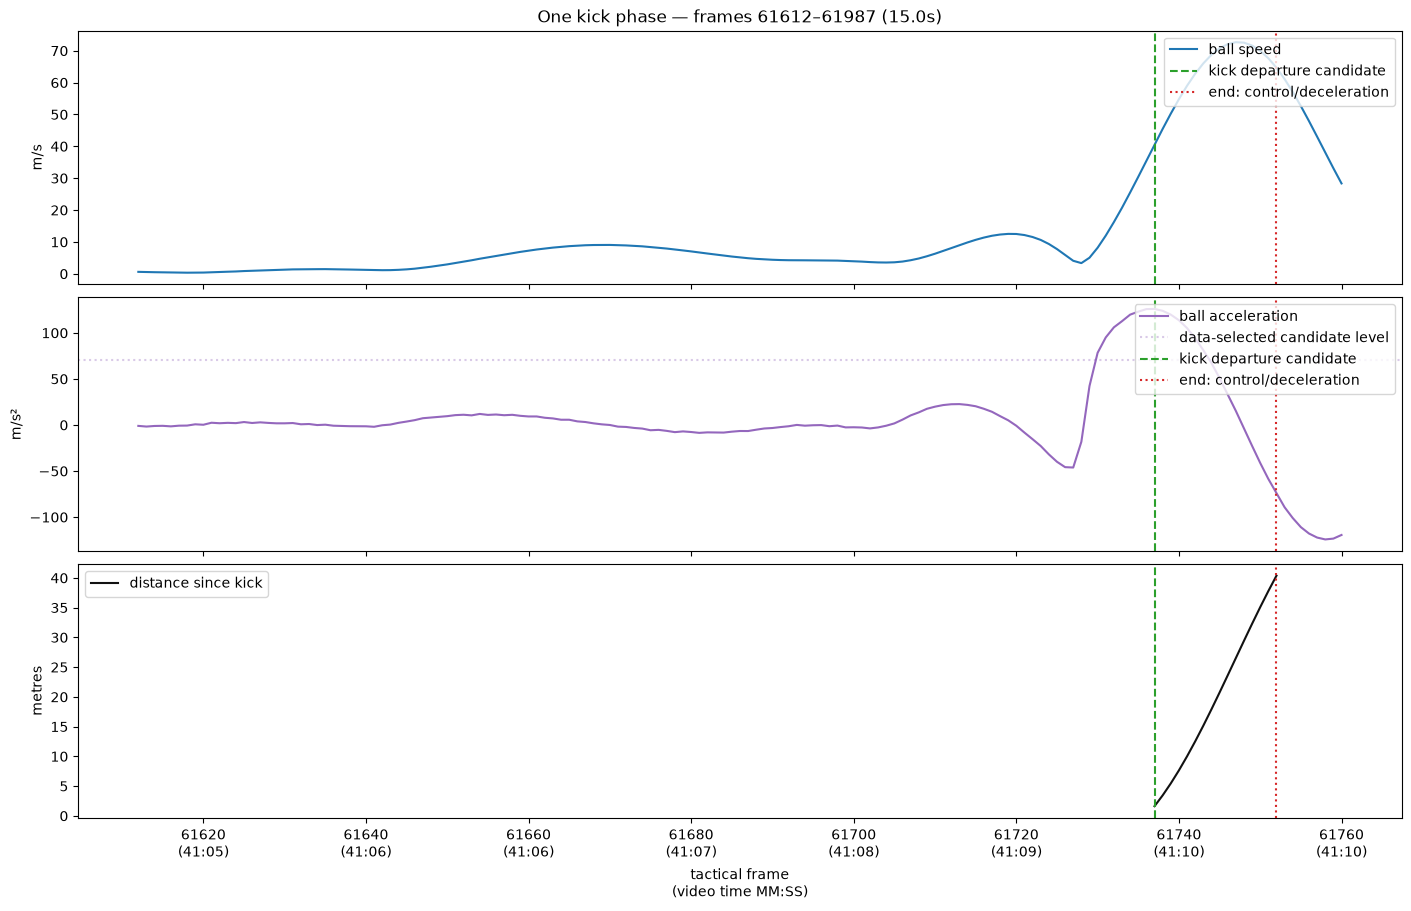

In [2]:
audit = public.copy()
audit['speed_mps'] = pd.to_numeric(audit['ball_speed_derived_mps'], errors='coerce')
audit['acceleration_mps2'] = pd.to_numeric(audit['ball_acceleration_mps2'], errors='coerce')
audit['step_distance_m'] = pd.to_numeric(audit['ball_displacement_m'], errors='coerce')
observed = audit.ball_x.notna() & audit.ball_y.notna()
speed_cut = audit.loc[observed, 'speed_mps'].quantile(0.75)
accel_cut = audit.loc[observed, 'acceleration_mps2'].quantile(0.99)
raw_candidates = audit.index[observed & audit.speed_mps.ge(speed_cut) & audit.acceleration_mps2.ge(accel_cut)]
kick_candidates = []
for idx in raw_candidates:
    frame = int(audit.loc[idx, 'frame'])
    if not kick_candidates or frame - kick_candidates[-1] >= 10:
        kick_candidates.append(frame)
    elif audit.loc[idx, 'acceleration_mps2'] > audit.loc[audit.frame.eq(kick_candidates[-1]), 'acceleration_mps2'].iloc[0]:
        kick_candidates[-1] = frame
kick_candidates = kick_candidates[:8]

FPS = 25
PHASE_LEAD_IN_S = 5
PHASE_AFTER_KICK_S = 10
phase_kick_frame = kick_candidates[0] if kick_candidates else int((PUBLIC_START + PUBLIC_END) / 2)
phase_start = max(PUBLIC_START, phase_kick_frame - PHASE_LEAD_IN_S * FPS)
phase_end = min(PUBLIC_END, phase_kick_frame + PHASE_AFTER_KICK_S * FPS)
phase = audit.loc[audit.frame.between(phase_start, phase_end)].copy()
phase['dx_m'] = phase.ball_x.diff()
phase['dy_m'] = phase.ball_y.diff()
phase['direction_change_deg'] = np.degrees(np.abs(np.angle(np.exp(1j * (np.arctan2(phase.dy_m, phase.dx_m).diff())))))
post_kick = phase[phase.frame.ge(phase_kick_frame)].copy()
minimum_event_gap = 8
deceleration_cut = audit.loc[observed, 'acceleration_mps2'].quantile(0.01)
control_candidates = post_kick.loc[
    post_kick.frame.ge(phase_kick_frame + minimum_event_gap)
    & post_kick.acceleration_mps2.le(deceleration_cut), 'frame'
]
turn_candidates = post_kick.loc[
    post_kick.frame.ge(phase_kick_frame + minimum_event_gap)
    & post_kick.direction_change_deg.ge(45), 'frame'
]
next_kick_candidates = post_kick.loc[
    post_kick.frame.ge(phase_kick_frame + minimum_event_gap)
    & post_kick.acceleration_mps2.ge(accel_cut), 'frame'
]
event_candidates = [
    (int(frame), 'control/deceleration') for frame in control_candidates
] + [
    (int(frame), 'direction change') for frame in turn_candidates
] + [
    (int(frame), 'next acceleration') for frame in next_kick_candidates
]
event_candidates.sort(key=lambda item: item[0])
event_frame, event_kind = event_candidates[0] if event_candidates else (phase_end, 'end of study window')
distance_end = min(event_frame, phase_end)
post_kick = post_kick[post_kick.frame.le(distance_end)].copy()
post_kick['distance_since_kick_m'] = post_kick.step_distance_m.fillna(0).cumsum()
episode_table = pd.DataFrame([{
    'kick_frame': phase_kick_frame,
    'distance_end_frame': distance_end,
    'distance_end_proxy': event_kind,
    'distance_m': float(post_kick['distance_since_kick_m'].iloc[-1]) if not post_kick.empty else 0.0,
}])
display(episode_table)

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True, constrained_layout=True)
axes[0].plot(phase.frame, phase.speed_mps, color='#1f77b4', label='ball speed')
axes[0].axvline(phase_kick_frame, color='#2ca02c', linestyle='--', label='kick departure candidate')
axes[0].axvline(distance_end, color='#d62728', linestyle=':', label=f'end: {event_kind}')
axes[0].set_ylabel('m/s')
axes[0].set_title(f'One kick phase — frames {phase_start}–{phase_end} ({(phase_end-phase_start)/FPS:.1f}s)')
axes[0].legend(loc='upper right')
axes[1].plot(phase.frame, phase.acceleration_mps2, color='#9467bd', label='ball acceleration')
axes[1].axhline(accel_cut, color='#9467bd', alpha=0.35, linestyle=':', label='data-selected candidate level')
axes[1].axvline(phase_kick_frame, color='#2ca02c', linestyle='--', label='kick departure candidate')
axes[1].axvline(distance_end, color='#d62728', linestyle=':', label=f'end: {event_kind}')
axes[1].set_ylabel('m/s²')
axes[1].legend(loc='upper right')
axes[2].plot(post_kick.frame, post_kick.distance_since_kick_m, color='#111111', label='distance since kick')
axes[2].axvline(phase_kick_frame, color='#2ca02c', linestyle='--')
axes[2].axvline(distance_end, color='#d62728', linestyle=':')
axes[2].set_ylabel('metres')
axes[2].set_xlabel('tactical frame / video time')
_apply_frame_time_axis(axes[2])
axes[2].legend(loc='upper left')
plt.show()


## How later notebooks use these signals

- **Kick/pass:** acceleration starts an episode; distance and direction describe the flight.
- **Control/reception:** deceleration, local distance minimum, and subsequent low speed close an episode.
- **Dribble:** small speed changes plus a player path that stays with the ball support continuity.
- **Deflection/tackle risk:** a new acceleration with direction change keeps the state unresolved; opponent proximity and the subsequent path decide whether a turnover is plausible.
- **Long-ball contest:** travel distance, landing speed, density, and closing speed are combined in notebook 03 rather than treated as separate possession labels.

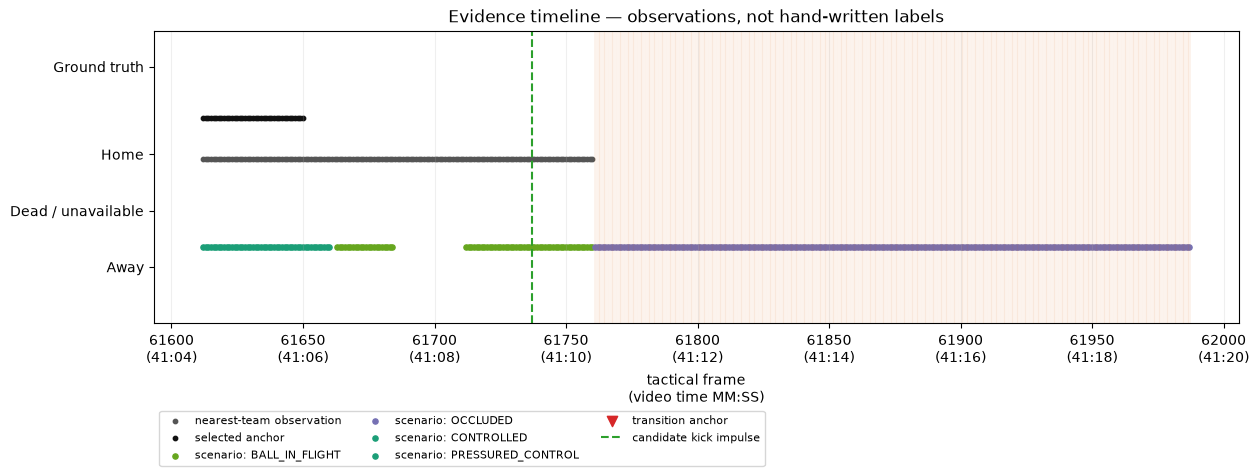

In [3]:
# Public ground truth is used only to choose and audit the study window. It never builds the features.
if gt is None:
    print('Public ground truth is not available in this checkout.')
else:
    start = max(PUBLIC_START, phase_start)
    end = min(PUBLIC_END, phase_end)
    fig, ax = plt.subplots(figsize=(14, 3.8))
    plot_timeline_window(features, start, end, ground_truth=gt, ax=ax)
    ax.axvline(phase_kick_frame, color='#2ca02c', linestyle='--', label='candidate kick impulse')
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.28), ncol=3, fontsize=8)
    plt.show()


## Takeaway

The reusable unit is not a label; it is a measurable pattern with a limitation. Notebook 03 combines these modular cases into scenario context, notebook 04 evaluates whether evidence is strong enough for an anchor, and the transition/decoder notebooks decide how conservatively to use those anchors over time.